In [24]:
# Notebook setup: ensure project root and analysis modules are on sys.path
# Run this notebook from the project root (music_topic/), not from notebooks/
import os, sys
from pathlib import Path

_here = Path(".").resolve()
_root = _here.parent if _here.name == "notebooks" else _here
os.chdir(_root)
for _p in [str(_root), str(_root / "backend" / "analysis"), str(_root / "backend" / "pipeline"), str(_root / "backend" / "export")]:
    if _p not in sys.path:
        sys.path.insert(0, _p)
print("Working directory:", os.getcwd())


Working directory: /Users/songhaifan/Documents/GitHub/music_topic


# Music Thumbnail Visualization — Project Pipeline

**目标：** 构建基于 audio embedding 与 interpretable feature 的 Theme & Variations 音乐可视化系统。

**使用说明：**
- 所有步骤按顺序执行

---
## Phase 0 — 环境 & 路径配置

In [25]:
from tv_core import TVDataset, Handcrafted, MERTEmbedder, Similarity, FrontendExporter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── Toggle while testing the downstream pipeline ──────────────────────────
USE_TEST_DATA = False
CSV_NAME = "TV_annotation_clean_test.csv" if USE_TEST_DATA else "TV_annotation_clean.csv"
OUTPUT_SUFFIX = "_test" if USE_TEST_DATA else ""

# ── Dataset subset ────────────────────────────────────────────────────────
# Change SUBSET to broaden or narrow the data passed through the pipeline.
#   'mbh_piano'       — Mozart / Beethoven / Haydn, piano only  (original)
#   'piano_classical' — Classical-period piano (all composers)
#   'piano_romantic'  — Romantic-period piano (all composers)
#   'piano_modern'    — Modern-period piano (all composers)
#   'piano_all'       — all piano works across all periods
#   'all'             — entire dataset, every instrument and period
SUBSET = "all"

ds = TVDataset(csv_name=CSV_NAME)
print(ds.paths)
print(f"Using CSV:     {CSV_NAME}")
print(f"Output suffix: {OUTPUT_SUFFIX or '(none)'}")
print(f"Subset:        {SUBSET}")

TVDataset: loaded 692 records from TV_annotation_clean.csv
Paths(root=/Users/songhaifan/Documents/GitHub/music_topic)
Using CSV:     TV_annotation_clean.csv
Output suffix: (none)
Subset:        all


In [26]:
df = ds.df
print(f'Records: {len(df)}')
ds.summary().T


Records: 692


,0
total,692
composers,47
Classical,377
Romantic,279
Modern,36
var_min,2
var_max,33


### Corpus Selection


In [27]:
# All helpers now live in tv_core.TVDataset.
# Labels:    ds.labels(row, which='core'|'extra'|'all')
# Wav path:  ds.segment_path(row, label)
# Iterator:  ds.iter_segments(df, which='core')
# Subset:    ds.subset('all')  /  ds.filter(composers=[...], instruments=[...])

---
## Phase 1 — Dataset Overview & Corpus Selection

### 1.1 数据集概览

In [28]:
# Period / instrument / variation_num 分布
print("=== Period 分布 ===")
print(df["period"].value_counts().to_string())
print()
print("=== 乐器前15 ===")
print(df["instrument"].value_counts().head(15).to_string())
print()
print("=== variation_num 分布 ===")
print(df["variation_num"].value_counts().sort_index().to_string())


=== Period 分布 ===
period
Classical    377
Romantic     279
Modern        36

=== 乐器前15 ===
instrument
piano                          461
piano-4hand                     61
Guitar                          40
cello; piano                    26
flute; piano                    22
harpsichord                     14
violin; cello; piano             9
harp                             8
flute; violin; viola; cello      7
strings                          6
clarinet; piano                  6
violin; piano                    5
oboe; horn                       5
organ                            4
Organ                            3

=== variation_num 分布 ===
variation_num
2     17
3     14
4     31
5     87
6     95
7     66
8     85
9     31
10    60
11    14
12    98
13    18
15    21
16     7
17     8
18     3
20     9
22     4
23     1
24     8
32     7
33     8


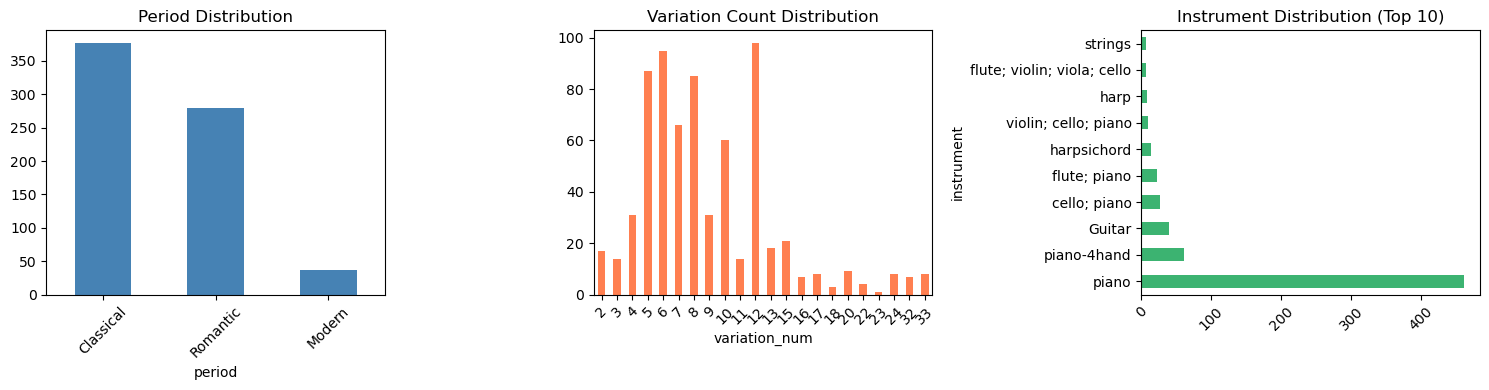

In [29]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df["period"].value_counts().plot(kind="bar", ax=axes[0], title="Period Distribution", color="steelblue")
df["variation_num"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Variation Count Distribution", color="coral")
df["instrument"].value_counts().head(10).plot(kind="barh", ax=axes[2], title="Instrument Distribution (Top 10)", color="mediumseagreen")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### 1.2 Corpus Selection — Mozart / Beethoven / Haydn piano 子集

In [30]:
df_mbh = ds.subset(SUBSET)
df_mbh.groupby(['period', 'composer']).size()


Subset 'all' (Full dataset — all composers, instruments, and periods): 692 records


period     composer                       
Classical  Carl Maria von Weber                 2
           Carl Philipp Emanuel Bach            2
           Christian Heinrich Rinck             1
           Fernando Sor                         7
           Friedrich Kuhlau                     3
           Johann Christoph Friedrich Bach      3
           Johann Nepomuk Hummel                5
           Joseph Haydn                        47
           Louis Spohr                          1
           Ludwig van Beethoven               169
           Muzio Clementi                       1
           Wolfgang Amadeus Mozart            136
Modern     Amy Beach                            6
           Arvo Pärt                            6
           Bohuslav Martinů                     8
           Carl Nielsen                         5
           Carlos Salzedo                       4
           Karol Szymanowski                    4
           Konstantin Eiges                     1
       

In [31]:
# Verify all core segment WAVs exist for MBH subset
missing = [(row['file_name (folderName_number)'], lbl)
           for row, lbl, wav in ds.iter_segments(df_mbh)
           if not wav.exists()]
print(f'Missing: {len(missing)}')


Missing: 0


---
## Phase 2.1 — Handcrafted Feature Extraction

每个音频片段（T / V1 / V2 ...）提取以下维度的特征（共约 35 维）：

| 维度 | 特征 |
|------|------|
| Pitch | mean_pitch, pitch_range, pitch_variance, contour_changes, upward_ratio, leap_ratio |
| Rhythm | onset_density, tempo_stability, note_density, rhythmic_variance |
| Dynamics | rms_mean, rms_variance |
| Harmony | chroma_entropy, tonal_centroid, harmonic_stability |
| Timbre | spectral_centroid_mean, spectral_brightness, mfcc_mean×13, mfcc_var×13 |

所有逻辑封装在 `tv_core.Handcrafted`，notebook 里只需调用 API。


In [32]:
# pip install librosa  (if needed)
hc = Handcrafted()

# Quick test on one segment
# test_row  = df_mbh.iloc[0]
# test_lbl  = ds.labels(test_row)[0]
# test_wav  = ds.segment_path(test_row, test_lbl)
# test_feat = hc.extract_one(test_wav)
# print(f'Features: {len(test_feat)}')
# print({k: round(v, 4) for k, v in list(test_feat.items())[:8]})


In [33]:
# Batch extraction — MBH piano subset (core labels: T, V1..Vn)
# In test mode, saves to features/handcrafted_features_test.csv.
out_name = f"handcrafted_features{OUTPUT_SUFFIX}.csv"
df_feat = hc.extract_batch(df_mbh, ds, out_name=out_name)
print(df_feat.shape)
df_feat.head(3)


Resume: loaded 7193 cached rows from /Users/songhaifan/Documents/GitHub/music_topic/features/handcrafted_features.csv

Saved 7193 rows → /Users/songhaifan/Documents/GitHub/music_topic/features/handcrafted_features.csv
Cached reused: 7193
Newly extracted: 0
(7193, 49)


,file_name,composer,piece,period,instrument,label,mean_pitch,pitch_range,pitch_variance,contour_changes,...,mfcc_mean_8,mfcc_var_8,mfcc_mean_9,mfcc_var_9,mfcc_mean_10,mfcc_var_10,mfcc_mean_11,mfcc_var_11,mfcc_mean_12,mfcc_var_12
0,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,T,253.643568,2139.763314,83347.520889,1207.0,...,-4.969315,76.926178,-5.192986,75.479591,-10.629039,93.728638,-4.970438,110.646187,-2.653893,120.179764
1,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,V1,238.360734,2139.763314,127102.943583,603.0,...,-10.174488,107.537766,-6.573583,88.774902,-15.964474,113.135284,-7.570473,108.641235,-3.880898,122.756035
2,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,V2,221.632150,2139.763314,70593.163889,888.0,...,-7.030590,95.776848,-4.461956,111.519035,-10.472809,119.267784,-7.069770,80.218208,-4.708056,94.427940


---
## Phase 2.2 — MERT Audio Embedding


使用 **MERT-v1-330M** 提取每个片段的 1024-D embedding（mean pooling over frames）。

所有逻辑封装在 `tv_core.MERTEmbedder`，notebook 里只需调用 API。

> **注意：** 首次运行会下载模型（约 1.3 GB）。建议在有 GPU / MPS 的环境运行。


In [34]:
from tv_core import MERTEmbedder

me = MERTEmbedder()   # auto-detects cuda / mps / cpu


MERTEmbedder: device = mps, pooling = all_layers_mean


In [35]:
# Quick sanity test — one segment
import numpy as np
# test_row = df_mbh.iloc[0]
# test_lbl = ds.labels(test_row)[0]
# test_wav = ds.segment_path(test_row, test_lbl)
# print(f'Test: {test_wav}')

# emb_test = me.extract_one(test_wav)
# print(f'Shape : {emb_test.shape}')   # should be (1024,)
# print(f'Norm  : {np.linalg.norm(emb_test):.3f}')
# print(f'First5: {emb_test[:5]}')


In [36]:
# Batch extraction — MBH piano subset
# In test mode, writes separate aggregate files so full MERT outputs are not overwritten.
emb_name = f"embeddings{OUTPUT_SUFFIX}.npy"
meta_name = f"embedding_meta{OUTPUT_SUFFIX}.csv"
index_name = f"mert_embedding_index{OUTPUT_SUFFIX}.csv"
emb_matrix, df_emb_meta = me.extract_batch(
    df_mbh,
    ds,
    emb_name=emb_name,
    meta_name=meta_name,
    index_name=index_name,
)
print(f'Matrix : {emb_matrix.shape}')   # test: (50, 1024); full: (N, 1024)
print(df_emb_meta.head())


Segments total: 7193
Segments cached: 7193
Segments to embed: 0

Saved embeddings → /Users/songhaifan/Documents/GitHub/music_topic/embeddings/embeddings.npy  (7193, 1024)
Saved metadata   → /Users/songhaifan/Documents/GitHub/music_topic/embeddings/embedding_meta.csv  7193 rows
Saved index      → /Users/songhaifan/Documents/GitHub/music_topic/embeddings/mert_embedding_index.csv
Matrix : (7193, 1024)
            file_name  composer    period label  \
0  Variouse_Russian_1  Variouse  Romantic     T   
1  Variouse_Russian_1  Variouse  Romantic    V1   
2  Variouse_Russian_1  Variouse  Romantic    V2   
3  Variouse_Russian_1  Variouse  Romantic    V3   
4  Variouse_Russian_1  Variouse  Romantic    V4   

                                      embedding_path          pooling  
0  embeddings/mert_embeddings/Variouse_Russian/Va...  all_layers_mean  
1  embeddings/mert_embeddings/Variouse_Russian/Va...  all_layers_mean  
2  embeddings/mert_embeddings/Variouse_Russian/Va...  all_layers_mean  
3  

---
## Phase 3 — Similarity Analysis

### 3.1 Pairwise Cosine Similarity Matrix

In [37]:
# Build/load similarity matrix for the current embedding output.
from tv_core import MERTEmbedder, Similarity

emb_name = f"embeddings{OUTPUT_SUFFIX}.npy"
meta_name = f"embedding_meta{OUTPUT_SUFFIX}.csv"
sim_name = f"cosine_similarity{OUTPUT_SUFFIX}.npy"

if "emb_matrix" not in locals() or "df_emb_meta" not in locals():
    emb_matrix, df_emb_meta = MERTEmbedder.load(ds, emb_name=emb_name, meta_name=meta_name)

sim = Similarity(emb_matrix, df_emb_meta)
sim.save(ds, name=sim_name)
print(f"Similarity matrix: {sim.matrix.shape}")


Saved similarity matrix → /Users/songhaifan/Documents/GitHub/music_topic/embeddings/cosine_similarity.npy  (7193, 7193)
Similarity matrix: (7193, 7193)


### 3.1.5 Handcrafted Feature Selection — Composer Target

目标：以 `composer` 作为 target，评估哪些 handcrafted audio features 对区分作曲家最有用。

注意：`file_name`、`composer`、`piece`、`period`、`instrument`、`label` 等 metadata 只用于对齐或作为 target，不参与 feature selection，避免从文件名或属性中泄漏作曲家信息。


In [38]:
# Composer-target feature selection using handcrafted audio features only.
# This excludes file_name/composer/piece/period/instrument/label and other metadata leakage columns.
from feature_selection import HandcraftedFeatureSelector

feat_name = f"handcrafted_features{OUTPUT_SUFFIX}.csv"
if "df_feat" not in locals():
    df_feat = pd.read_csv(ds.paths.features / feat_name)

selector = HandcraftedFeatureSelector(target_col="composer", verbose=True)
selection, group_summary = selector.run(
    df_feat=df_feat,
    ds=ds,
    output_suffix=OUTPUT_SUFFIX,
    save=True,
    top_n=20,
)

display(selection.head(20))
display(group_summary)


[1/6] Preparing target and audio feature matrix
      rows: 7193
      target classes: {'Alexander Glazunov': np.int64(128), 'Alfredo Casella': np.int64(77), 'Amy Beach': np.int64(79), 'Anatoly Lyadov': np.int64(107), 'Anton Arensky': np.int64(40), 'Anton Rubinstein': np.int64(13), 'Antonín Dvořák': np.int64(36), 'Arvo Pärt': np.int64(36), 'Bohuslav Martinů': np.int64(48), 'Carl Maria von Weber': np.int64(133), 'Carl Nielsen': np.int64(80), 'Carl Philipp Emanuel Bach': np.int64(25), 'Carlos Salzedo': np.int64(48), 'Charles-Valentin Alkan': np.int64(14), 'Christian Heinrich Rinck': np.int64(7), 'Clara Schumann': np.int64(56), 'Felix Mendelssohn': np.int64(180), 'Fernando Sor': np.int64(225), 'Franz Schubert': np.int64(488), 'Friedrich Kuhlau': np.int64(23), 'Frédéric Chopin': np.int64(95), 'Gabriel Fauré': np.int64(72), 'Giuseppe Martucci': np.int64(20), 'Gustav Merkel': np.int64(24), 'Ignaz Friedman': np.int64(36), 'Jan Václav Voříšek': np.int64(14), 'Johann Christoph Friedrich Bach': 

,overall_rank,feature,group,anova_f,anova_p,mutual_info,rf_importance,l1_abs_coef,rank_anova_f,rank_mutual_info,rank_rf_importance,rank_l1_abs_coef,mean_rank
0,1,tonal_centroid,harmony,42.464228,0.000000e+00,0.181181,0.033989,0.708360,1.0,5.0,2.0,6.0,3.50
1,2,mfcc_mean_1,timbre_mfcc,36.813970,0.000000e+00,0.168243,0.030498,0.802666,6.0,7.0,6.0,3.0,5.50
2,3,contour_changes,pitch,30.413204,2.688143e-238,0.226275,0.039704,0.772860,14.0,2.0,1.0,5.0,5.50
3,4,mfcc_mean_3,timbre_mfcc,37.908368,0.000000e+00,0.173188,0.031874,0.640344,5.0,6.0,3.0,12.0,6.50
4,5,mean_pitch,pitch,33.087698,8.227024e-260,0.156739,0.027870,0.787941,10.0,9.0,8.0,4.0,7.75
5,6,mfcc_mean_10,timbre_mfcc,28.078954,2.575745e-219,0.144383,0.027255,0.700131,19.0,14.0,9.0,7.0,12.25
6,7,spectral_brightness,timbre,31.800542,1.729917e-249,0.148568,0.031437,0.508114,12.0,11.0,4.0,24.0,12.75
7,8,chroma_entropy,harmony,28.253533,9.655121e-221,0.104793,0.028706,0.922587,18.0,25.0,7.0,1.0,12.75
8,9,spectral_centroid_mean,timbre,31.800542,1.729917e-249,0.148564,0.031029,0.508114,13.0,12.0,5.0,25.0,13.75
9,10,mfcc_var_12,timbre_mfcc,39.468557,0.000000e+00,0.144795,0.022508,0.509340,2.0,13.0,21.0,23.0,14.75


,group,n_features,top10_count,best_rank,mean_rank,mean_rf_importance,mean_mutual_info
0,timbre_mfcc,26,4,2,21.692308,0.022754,0.109048
1,harmony,3,2,1,8.000000,0.029313,0.125516
2,pitch,6,2,3,18.333333,0.023759,0.195240
3,timbre,2,2,7,8.000000,0.031233,0.148566
4,rhythm,4,0,35,39.000000,0.017734,0.094764
5,dynamics,2,0,37,38.000000,0.022250,0.074701


### 3.2 Dimensionality Reduction（UMAP / t-SNE / PCA）

In [39]:
from reduction import SegmentReducer

FEATURE_SPACE = "embedding"  # "embedding" or "handcrafted"

reducer = SegmentReducer(feature_space=FEATURE_SPACE, verbose=True)
X_model, plot_meta = reducer.prepare(
    emb_matrix=emb_matrix,
    df_emb_meta=df_emb_meta,
    df_feat=df_feat if FEATURE_SPACE == "handcrafted" else None,
)
df_reduction = reducer.run(
    X_model=X_model,
    plot_meta=plot_meta,
    ds=ds,
    output_suffix=OUTPUT_SUFFIX,
    save=True,
)

Feature space : embedding
Input matrix  : (7193, 1024)
[1/3] PCA
[2/3] UMAP  (n_neighbors=15)
[3/3] t-SNE (perplexity=30.0)
Saved reduction -> /Users/songhaifan/Documents/GitHub/music_topic/embeddings/reduction_embedding.csv


In [40]:
# Quick inspection of the reduction table.
df_reduction.head()


,file_name,composer,period,label,embedding_path,pooling,pca_x,pca_y,umap_x,umap_y,tsne_x,tsne_y
0,Variouse_Russian_1,Variouse,Romantic,T,embeddings/mert_embeddings/Variouse_Russian/Va...,all_layers_mean,31.134390,25.291979,4.627567,-0.731267,67.778145,39.658596
1,Variouse_Russian_1,Variouse,Romantic,V1,embeddings/mert_embeddings/Variouse_Russian/Va...,all_layers_mean,35.657593,12.990858,4.610384,-0.726467,68.111130,39.608421
2,Variouse_Russian_1,Variouse,Romantic,V2,embeddings/mert_embeddings/Variouse_Russian/Va...,all_layers_mean,35.638000,14.859403,4.636537,-0.762604,67.944550,39.516987
3,Variouse_Russian_1,Variouse,Romantic,V3,embeddings/mert_embeddings/Variouse_Russian/Va...,all_layers_mean,11.515697,16.836647,2.926884,-1.739663,61.954269,26.208553
4,Variouse_Russian_1,Variouse,Romantic,V4,embeddings/mert_embeddings/Variouse_Russian/Va...,all_layers_mean,26.064392,45.447742,3.464972,1.081457,40.667435,59.730568


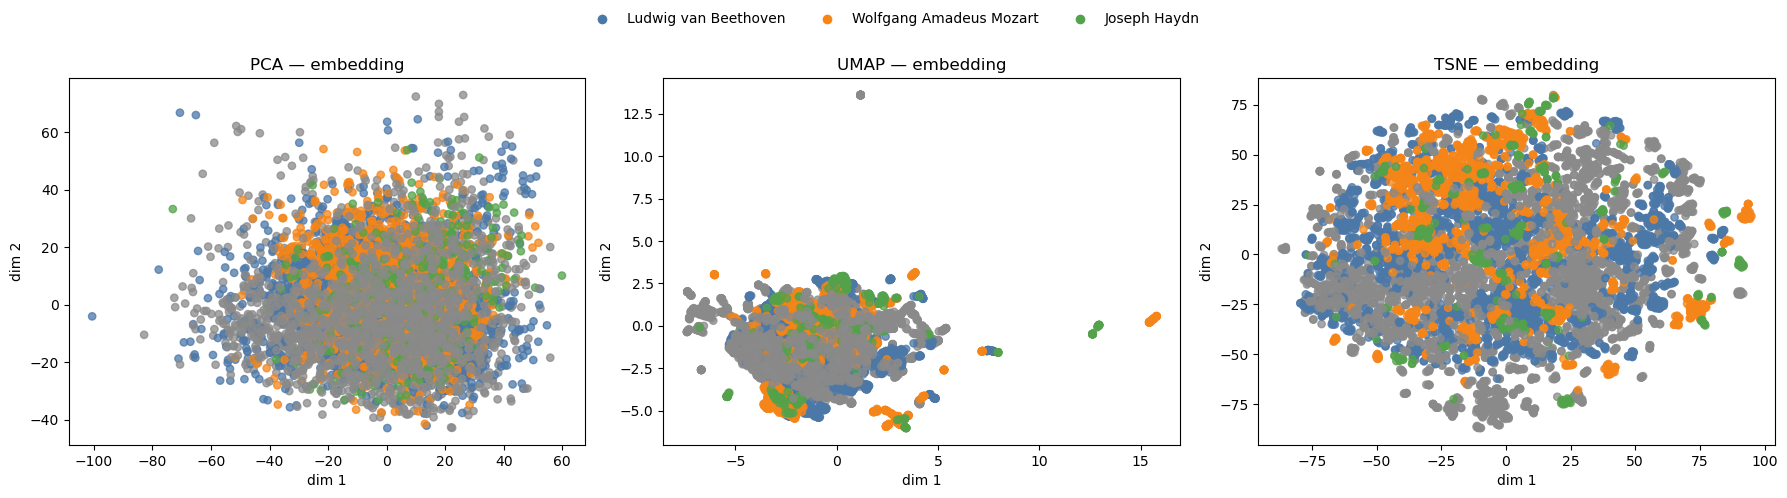

In [41]:
reducer.plot(df_reduction)
plt.show()

### 3.3 Clustering

[1/3] PCA: 1024D -> 58D (explained variance: 0.950)
[2/3] Silhouette sweep k=3..10
      k=3: 0.1196 <-- best
      k=4: 0.0875
      k=5: 0.0930
      k=6: 0.0846
      k=7: 0.0864
      k=8: 0.0711
      k=9: 0.0679
      k=10: 0.0620
Saved clusters -> /Users/songhaifan/Documents/GitHub/music_topic/embeddings/clusters_embedding.csv

KMeans cluster distribution (K=3):
0    2242
1    2794
2    2157


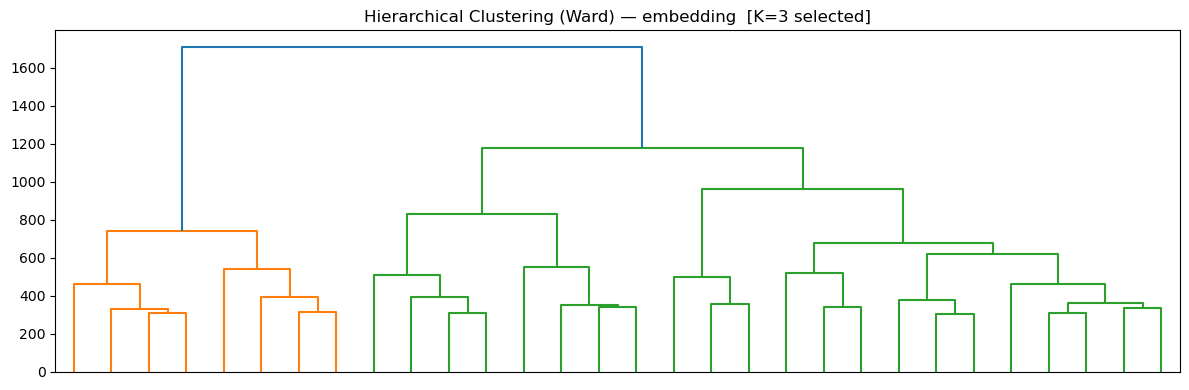

In [42]:
from clustering import SegmentClusterer

clusterer = SegmentClusterer(
    clusters=None,      # None = auto-select via silhouette; set int to fix K
    min_k=3,
    max_k=10,
    pca_variance=0.95,
    random_state=42,
    verbose=True,
)

df_clusters, metrics = clusterer.run(
    X_model=X_model,
    plot_meta=plot_meta,
    ds=ds,
    feature_space=FEATURE_SPACE,
    output_suffix=OUTPUT_SUFFIX,
    save=True,
)

clusterer.plot_dendrogram()
plt.show()

---
## Phase 4 — Visualization（Music Thumbnail）

**目标：** 为每个 segment / variation 生成一张紧凑、可比较的 **waveform thumbnail**。

| 元素 | 含义 |
|------|------|
| inner spokes | Phase 3 选出的 top handcrafted features |
| spoke length | 该 segment 的 robust-normalized feature value |
| spoke color | feature group（pitch / rhythm / dynamics / harmony / timbre / MFCC） |
| outer contour | 该 segment 的 waveform line，映射成 circular audio contour |
| gallery order | `T, V1, V2, ...`，用于比较同一 recording 内主题与变奏 |

Waveform Thumbnail 同时包含 selected-feature profile 和直接音频波形形状，是 Phase 4 的主输出。


In [43]:
# Load handcrafted features and selected-feature ranking.
from visualization import MusicThumbnailRenderer

feat_name = f"handcrafted_features{OUTPUT_SUFFIX}.csv"
selection_name = f"handcrafted_feature_selection_composer{OUTPUT_SUFFIX}.csv"

df_feat = pd.read_csv(ds.paths.features / feat_name)
selection = pd.read_csv(ds.paths.features / selection_name)

print(f"Handcrafted features: {df_feat.shape}")
print(f"Feature selection ranking: {selection.shape}")
selection.head(10)


Handcrafted features: (7193, 49)
Feature selection ranking: (43, 13)


,overall_rank,feature,group,anova_f,anova_p,mutual_info,rf_importance,l1_abs_coef,rank_anova_f,rank_mutual_info,rank_rf_importance,rank_l1_abs_coef,mean_rank
0,1,tonal_centroid,harmony,42.464228,0.000000e+00,0.181181,0.033989,0.708360,1.0,5.0,2.0,6.0,3.50
1,2,mfcc_mean_1,timbre_mfcc,36.813970,0.000000e+00,0.168243,0.030498,0.802666,6.0,7.0,6.0,3.0,5.50
2,3,contour_changes,pitch,30.413204,2.688143e-238,0.226275,0.039704,0.772860,14.0,2.0,1.0,5.0,5.50
3,4,mfcc_mean_3,timbre_mfcc,37.908368,0.000000e+00,0.173188,0.031874,0.640344,5.0,6.0,3.0,12.0,6.50
4,5,mean_pitch,pitch,33.087698,8.227024e-260,0.156739,0.027870,0.787941,10.0,9.0,8.0,4.0,7.75
5,6,mfcc_mean_10,timbre_mfcc,28.078954,2.575745e-219,0.144383,0.027255,0.700131,19.0,14.0,9.0,7.0,12.25
6,7,spectral_brightness,timbre,31.800542,1.729917e-249,0.148568,0.031437,0.508114,12.0,11.0,4.0,24.0,12.75
7,8,chroma_entropy,harmony,28.253533,9.655121e-221,0.104793,0.028706,0.922587,18.0,25.0,7.0,1.0,12.75
8,9,spectral_centroid_mean,timbre,31.800542,1.729917e-249,0.148564,0.031029,0.508114,13.0,12.0,5.0,25.0,13.75
9,10,mfcc_var_12,timbre_mfcc,39.468557,0.000000e+00,0.144795,0.022508,0.509340,2.0,13.0,21.0,23.0,14.75


In [44]:
# Prepare thumbnail input table from the selected handcrafted features.
renderer = MusicThumbnailRenderer(top_n_features=8, verbose=True)
thumbnail_df = renderer.prepare(
    df_feat=df_feat,
    selection=selection,
    ds=ds,
    output_suffix=OUTPUT_SUFFIX,
    save=True,
)

selected_features = thumbnail_df.attrs["thumbnail_features"]
feature_to_group = thumbnail_df.attrs["feature_to_group"]

print("Selected thumbnail features:")
for i, feature in enumerate(selected_features, start=1):
    print(f"{i}. {feature} ({feature_to_group.get(feature, 'other')})")

thumbnail_df.head(3)


[1/4] Selecting top handcrafted features
      top features: ['tonal_centroid', 'mfcc_mean_1', 'contour_changes', 'mfcc_mean_3', 'mean_pitch', 'mfcc_mean_10', 'spectral_brightness', 'chroma_entropy']
[2/4] Normalizing selected audio feature values
      rows: 7193
      normalized columns: 8
[3/4] Saving thumbnail feature table
      saved -> /Users/songhaifan/Documents/GitHub/music_topic/features/thumbnail_features.csv
[4/4] Ready to render thumbnails
Selected thumbnail features:
1. tonal_centroid (harmony)
2. mfcc_mean_1 (timbre_mfcc)
3. contour_changes (pitch)
4. mfcc_mean_3 (timbre_mfcc)
5. mean_pitch (pitch)
6. mfcc_mean_10 (timbre_mfcc)
7. spectral_brightness (timbre)
8. chroma_entropy (harmony)


,file_name,composer,piece,period,instrument,label,tonal_centroid,mfcc_mean_1,contour_changes,mfcc_mean_3,...,spectral_brightness,chroma_entropy,norm_tonal_centroid,norm_mfcc_mean_1,norm_contour_changes,norm_mfcc_mean_3,norm_mean_pitch,norm_mfcc_mean_10,norm_spectral_brightness,norm_chroma_entropy
0,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,T,5.473514,104.617332,1207.0,20.678299,...,0.150104,2.416160,0.528062,0.0,0.670503,0.951221,0.556001,0.181053,1.0,0.605177
1,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,V1,5.598796,120.031578,603.0,29.498672,...,0.142269,2.419703,0.646189,0.0,0.266328,1.000000,0.489382,0.000000,1.0,0.635470
2,Variouse_Russian_1,Variouse,Variations on a Russian theme in G major,Romantic,violin; viola; cello,V2,5.691789,117.223038,888.0,18.590919,...,0.143894,2.414975,0.733870,0.0,0.457040,0.899987,0.416461,0.191797,1.0,0.595050


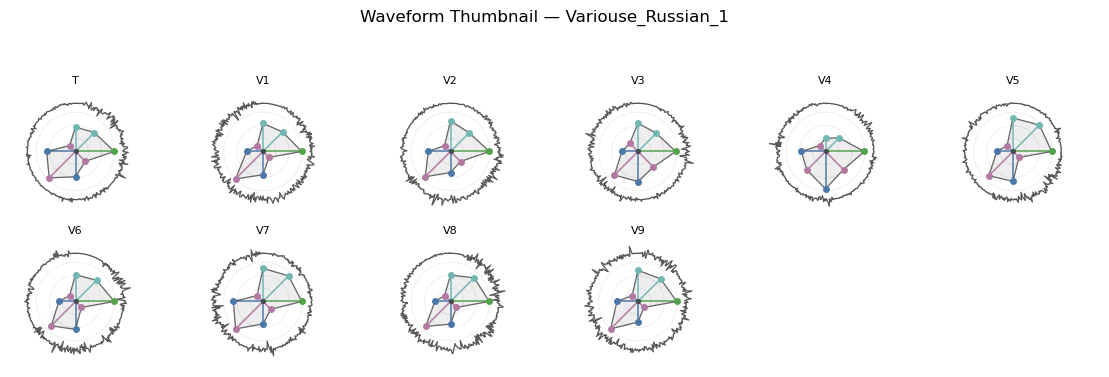



,file_name,label,norm_tonal_centroid,norm_mfcc_mean_1,norm_contour_changes,norm_mfcc_mean_3,norm_mean_pitch,norm_mfcc_mean_10,norm_spectral_brightness,norm_chroma_entropy
0,Variouse_Russian_1,T,0.528062,0.000000,0.670503,0.951221,0.556001,0.181053,1.000000,0.605177
1,Variouse_Russian_1,V1,0.646189,0.000000,0.266328,1.000000,0.489382,0.000000,1.000000,0.635470
2,Variouse_Russian_1,V2,0.733870,0.000000,0.457040,0.899987,0.416461,0.191797,1.000000,0.595050
3,Variouse_Russian_1,V3,0.654297,0.109595,0.254283,0.819786,0.713619,0.444201,0.966733,0.575709
4,Variouse_Russian_1,V4,0.158833,0.000000,0.521949,0.588065,0.952712,0.563858,1.000000,0.358501


In [45]:
# Waveform Thumbnail Gallery: one recording, T then V1/V2/...
example_file = thumbnail_df["file_name"].iloc[0]
fig, axes, waveform_thumbnail_df = renderer.render_waveform_thumbnail_gallery(
    thumbnail_df=thumbnail_df,
    df_records=df_mbh,
    ds=ds,
    file_name=example_file,
    selected_features=selected_features,
    feature_to_group=feature_to_group,
    title=f"Waveform Thumbnail — {example_file}",
)

renderer.feature_legend(selected_features, feature_to_group)
plt.show()

waveform_thumbnail_df[["file_name", "label"] + [f"norm_{f}" for f in selected_features]].head()


---
## Phase 5 — Export Frontend Data

Builds the two files that `explorer_app` reads at runtime:
- `explorer_app/src/data/segment_visualization{suffix}.csv` — one row per segment: metadata, t-SNE coords, cluster, and top-N feature values
- `explorer_app/src/data/waveform_thumbnails{suffix}.json` — waveform shape + normalised feature profile per segment

Uses in-memory variables from Phases 0–4 (nothing re-read from disk).
After this cell, rebuild the frontend with `cd explorer_app && npm run build`.


In [46]:
from tv_core import FrontendExporter

# All inputs come from earlier phases — no disk reads.
# USE_TEST_DATA / OUTPUT_SUFFIX are set in Phase 0 and control the output filenames.
exporter = FrontendExporter(ds, top_n_features=8, verbose=True)

result = exporter.run(
    df_ann         = ds.df,          # raw annotation DataFrame (Phase 0)
    df_reduction   = df_reduction,   # t-SNE coords (Phase 3.2)
    df_clusters    = df_clusters,    # cluster assignments (Phase 3.3)
    thumbnail_df   = thumbnail_df,   # normalised feature values (Phase 4)
    selection      = selection,      # feature ranking table (Phase 3.1.5)
    output_suffix  = OUTPUT_SUFFIX,  # '' for full data, '_test' for test subset
    waveform_points= 160,
    save           = True,
)

df_vis  = result['df_vis']
errors  = result['errors']
print(f'\nDone. {len(df_vis)} segments exported.')
if errors:
    print(f'{len(errors)} waveform warnings (audio files missing or unreadable).')


Selected features (8): ['tonal_centroid', 'mfcc_mean_1', 'contour_changes', 'mfcc_mean_3', 'mean_pitch', 'mfcc_mean_10', 'spectral_brightness', 'chroma_entropy']

Building segment_visualization CSV...
Building waveform_thumbnails JSON...
  -> /Users/songhaifan/Documents/GitHub/music_topic/explorer_app/src/data/segment_visualization.csv  (7193 rows)
  -> /Users/songhaifan/Documents/GitHub/music_topic/explorer_app/src/data/waveform_thumbnails.json  (7193 items)

Done. 7193 segments exported.
